# **Assignment-1 AI and Society**

## TASK 0 — Dataset Loading and Inspection

In [ ]:
%pip install ucimlrepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import statsmodels.api as sm
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

RANDOM_STATE = 888

print("All required libraries imported successfully.")
print("Random state:", RANDOM_STATE)

All required libraries imported successfully.
Random state: 888


In [ ]:
adult = fetch_ucirepo(id=2)

X_raw = adult.data.features.copy()
y_raw = adult.data.targets.copy()

df = pd.concat([X_raw, y_raw], axis=1)

df.columns = df.columns.str.strip()

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Dataset loaded successfully!")

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset loaded successfully!

Dataset shape:
(48842, 15)

Column names:
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']

First five rows:


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       47879 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      47876 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48568 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [ ]:
print("Missing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nUnknown '?' values in categorical columns:")

for col in df.select_dtypes(include="object").columns:
    count = (df[col] == "?").sum()

    if count > 0:
        print(f"{col}: {count}")

Missing values in each column:


,Missing Values
age,0
workclass,963
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,966
relationship,0
race,0
sex,0



Unknown '?' values in categorical columns:
workclass: 1836
occupation: 1843
native-country: 583


## TASK 1 — Data Preprocessing

In [ ]:
print(df.columns.tolist())

['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']


In [ ]:
# Replace unknown values with missing values
df = df.replace("?", np.nan)

# Remove rows only when the target is missing
df = df.dropna(subset=["income"]).copy()

# Display missing values
print("Missing values:")
display(df.isnull().sum().to_frame("Missing Values"))

# Convert income into a binary target
df["income_binary"] = df["income"].apply(
    lambda x: 1 if ">50K" in str(x) else 0
)

# Remove original income column
df = df.drop(columns=["income"])

Missing values:


,Missing Values
age,0
workclass,2799
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,2809
relationship,0
race,0
sex,0


In [ ]:
print("\nDataset shape after cleaning:")
print(df.shape)

print("\nMissing values after cleaning:")
display(df.isnull().sum().to_frame("Missing Values"))


Dataset shape after cleaning:
(48842, 15)

Missing values after cleaning:


,Missing Values
age,0
workclass,2799
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,2809
relationship,0
race,0
sex,0


In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns.drop(
    "income_binary",
    errors="ignore"
)

outlier_results = []

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    outlier_results.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count
    })

outlier_table = pd.DataFrame(outlier_results)

print("Outlier inspection using IQR:")
display(outlier_table)

Outlier inspection using IQR:


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,age,28.0,48.0,20.0,-2.00,78.00,216
1,fnlwgt,117550.5,237642.0,120091.5,-62586.75,417779.25,1453
2,education-num,9.0,12.0,3.0,4.50,16.50,1794
3,capital-gain,0.0,0.0,0.0,0.00,0.00,4035
4,capital-loss,0.0,0.0,0.0,0.00,0.00,2282
5,hours-per-week,40.0,45.0,5.0,32.50,52.50,13496


In [ ]:
X = df.drop(columns=["income_binary"])
y = df["income_binary"]

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nNumerical features:")
print(X.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical features:")
print(X.select_dtypes(include=["object", "category"]).columns.tolist())

Feature matrix shape: (48842, 14)
Target vector shape: (48842,)

Numerical features:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical features:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=888,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining target distribution (%):")
display(
    (y_train.value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage")
)

print("\nTesting target distribution (%):")
display(
    (y_test.value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage")
)

Training set shape: (34189, 14)
Testing set shape: (14653, 14)

Training target distribution (%):


,Percentage
income_binary,
0,76.07
1,23.93



Testing target distribution (%):


,Percentage
income_binary,
0,76.07
1,23.93


In [ ]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

Numerical features:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical features:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

Number of numerical features: 6
Number of categorical features: 8


In [ ]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            )
        )
    ]
)

# Combine numerical and categorical transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Fit on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data without fitting again
X_test_processed = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

Original training shape: (34189, 14)
Processed training shape: (34189, 97)

Original testing shape: (14653, 14)
Processed testing shape: (14653, 97)


### PART 1.1: TRAIN LINEAR REGRESSION (OLS)

In [ ]:
# Create the model
linear_model = LinearRegression()

# Train the model
linear_model.fit(
    X_train_processed,
    y_train
)

# Predict income scores on the test set
y_pred_linear = linear_model.predict(
    X_test_processed
)

print("LINEAR REGRESSION RESULTS")
print("=" * 50)

print("\nFirst 10 predictions:")
print(y_pred_linear[:10])

# Regression evaluation metrics
ols_mae = mean_absolute_error(
    y_test,
    y_pred_linear
)

ols_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_linear
    )
)

ols_r2 = r2_score(
    y_test,
    y_pred_linear
)

print("\nMean Absolute Error (MAE):", round(ols_mae, 4))
print("Root Mean Squared Error (RMSE):", round(ols_rmse, 4))
print("R-squared (R²):", round(ols_r2, 4))

print("\nMinimum prediction:", round(y_pred_linear.min(), 4))
print("Maximum prediction:", round(y_pred_linear.max(), 4))

print("\nPrediction statistics:")
display(
    pd.Series(y_pred_linear).describe().to_frame("OLS Predictions")
)

LINEAR REGRESSION RESULTS

First 10 predictions:
[ 0.23442066  0.17653092  0.40065876  0.18559303  0.41596831  0.25393467
  0.32004077  0.49174616 -0.01242828  0.87399557]

Mean Absolute Error (MAE): 0.2636
Root Mean Squared Error (RMSE): 0.3409
R-squared (R²): 0.3616

Minimum prediction: -0.3144
Maximum prediction: 1.7559

Prediction statistics:


,OLS Predictions
count,14653.000000
mean,0.239605
std,0.259024
min,-0.314383
25%,0.018473
50%,0.229390
75%,0.404519
max,1.755869


### PART 1.2: TRAIN LOGISTIC REGRESSION

In [ ]:
# Create and train the model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

logistic_model.fit(
    X_train_processed,
    y_train
)

# Predict probabilities for income > $50K
y_pred_logistic_prob = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

# Classify using threshold 0.5
y_pred_logistic = (
    y_pred_logistic_prob >= 0.5
).astype(int)

print("LOGISTIC REGRESSION RESULTS")
print("=" * 50)

print("\nFirst 10 predicted probabilities:")
print(y_pred_logistic_prob[:10])

print("\nFirst 10 predicted classes:")
print(y_pred_logistic[:10])

# Evaluate classification performance
logistic_accuracy = accuracy_score(
    y_test,
    y_pred_logistic
)

print("\nAccuracy:", round(logistic_accuracy, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_logistic,
        target_names=[
            "Income <= $50K",
            "Income > $50K"
        ],
        zero_division=0
    )
)

LOGISTIC REGRESSION RESULTS

First 10 predicted probabilities:
[0.05991745 0.08060674 0.35806515 0.02221701 0.39935444 0.07574729
 0.26881346 0.51301599 0.0138745  0.93566929]

First 10 predicted classes:
[0 0 0 0 0 0 0 1 0 1]

Accuracy: 0.8497

Classification Report:
                precision    recall  f1-score   support

Income <= $50K       0.88      0.93      0.90     11147
 Income > $50K       0.73      0.60      0.66      3506

      accuracy                           0.85     14653
     macro avg       0.80      0.76      0.78     14653
  weighted avg       0.84      0.85      0.84     14653



### PART 1.2A: LOGISTIC REGRESSION CONFUSION MATRIX

Confusion Matrix:
[[10355   792]
 [ 1411  2095]]


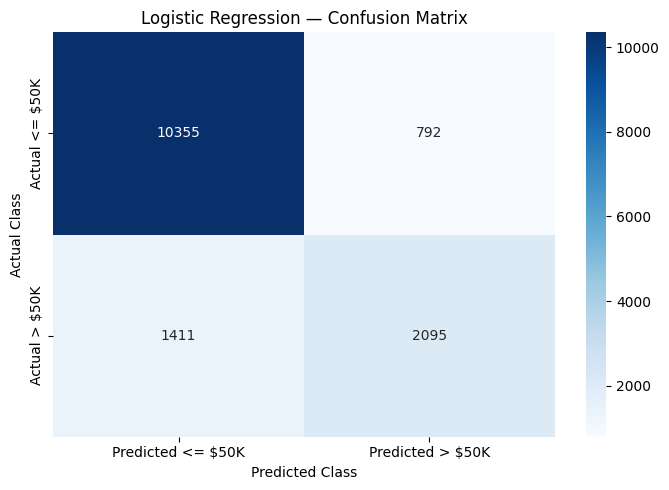

In [ ]:
cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm_logistic)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted <= $50K", "Predicted > $50K"],
    yticklabels=["Actual <= $50K", "Actual > $50K"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

### PART 1.3: COMPARE OLS AND LOGISTIC REGRESSION

In [ ]:
# OLS classification threshold = median prediction
ols_threshold = np.median(y_pred_linear)

ols_classification = (
    y_pred_linear >= ols_threshold
).astype(int)

# Logistic Regression threshold = 0.5
logistic_threshold = 0.5

logistic_classification = (
    y_pred_logistic_prob >= logistic_threshold
).astype(int)

print("OLS median threshold:", round(ols_threshold, 4))
print("Logistic Regression threshold:", logistic_threshold)

# Build comparison DataFrame
comparison_df = pd.DataFrame({
    "Actual_Income": y_test.to_numpy(),
    "OLS_Prediction": y_pred_linear,
    "OLS_Class": ols_classification,
    "Logistic_Probability": y_pred_logistic_prob,
    "Logistic_Class": logistic_classification
})

# Identify disagreements
comparison_df["Mismatch"] = (
    comparison_df["OLS_Class"] !=
    comparison_df["Logistic_Class"]
)

mismatch_count = int(
    comparison_df["Mismatch"].sum()
)

total_test_cases = len(comparison_df)

mismatch_percentage = (
    mismatch_count / total_test_cases
) * 100

print("\nTotal test cases:", total_test_cases)
print("Mismatched classifications:", mismatch_count)
print("Mismatch percentage:", round(mismatch_percentage, 2), "%")

print("\nFirst 10 comparison rows:")
display(comparison_df.head(10))

OLS median threshold: 0.2294
Logistic Regression threshold: 0.5

Total test cases: 14653
Mismatched classifications: 4492
Mismatch percentage: 30.66 %

First 10 comparison rows:


,Actual_Income,OLS_Prediction,OLS_Class,Logistic_Probability,Logistic_Class,Mismatch
0,0,0.234421,1,0.059917,0,True
1,0,0.176531,0,0.080607,0,False
2,0,0.400659,1,0.358065,0,True
3,0,0.185593,0,0.022217,0,False
4,0,0.415968,1,0.399354,0,True
5,0,0.253935,1,0.075747,0,True
6,0,0.320041,1,0.268813,0,True
7,0,0.491746,1,0.513016,1,False
8,0,-0.012428,0,0.013875,0,False
9,1,0.873996,1,0.935669,1,False


### PART 1.4: MODEL COMPARISON SUMMARY

In [ ]:
part1_summary = pd.DataFrame({
    "Metric": [
        "Test Set Size",
        "OLS MAE",
        "OLS RMSE",
        "OLS R-squared",
        "Logistic Regression Accuracy",
        "OLS Median Threshold",
        "Logistic Threshold",
        "Mismatched Predictions",
        "Mismatch Percentage"
    ],
    "Value": [
        total_test_cases,
        ols_mae,
        ols_rmse,
        ols_r2,
        logistic_accuracy,
        ols_threshold,
        logistic_threshold,
        mismatch_count,
        mismatch_percentage
    ]
})

display(part1_summary.round(4))

,Metric,Value
0,Test Set Size,14653.0000
1,OLS MAE,0.2636
2,OLS RMSE,0.3409
3,OLS R-squared,0.3616
4,Logistic Regression Accuracy,0.8497
5,OLS Median Threshold,0.2294
6,Logistic Threshold,0.5000
7,Mismatched Predictions,4492.0000
8,Mismatch Percentage,30.6558


## Part 2 — The Trap

### PART 2.1 — Simpson’s Paradox Hunt

In [ ]:
# Display available columns for subgroup analysis

print("Available columns:")
print(df.columns.tolist())

print("\nCategorical columns:")
print(df.select_dtypes(include=["object", "category"]).columns.tolist())

print("\nNumerical columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

Available columns:
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income_binary']

Categorical columns:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

Numerical columns:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week', 'income_binary']


In [ ]:
# Prepare data for statistical logistic regression

analysis_df = df.copy()

print("Dataset shape:", analysis_df.shape)
print("\nTarget distribution:")
print(analysis_df["income_binary"].value_counts())

print("\nPotential subgroup variables:")
for col in ["sex", "race", "workclass", "education", "marital-status"]:
    if col in analysis_df.columns:
        print(f"\n{col}:")
        print(analysis_df[col].value_counts())

Dataset shape: (48842, 15)

Target distribution:
income_binary
0    37155
1    11687
Name: count, dtype: int64

Potential subgroup variables:

sex:
sex
Male      32650
Female    16192
Name: count, dtype: int64

race:
race
White                 41762
Black                  4685
Asian-Pac-Islander     1519
Amer-Indian-Eskimo      470
Other                   406
Name: count, dtype: int64

workclass:
workclass
Private             33906
Self-emp-not-inc     3862
Local-gov            3136
State-gov            1981
Self-emp-inc         1695
Federal-gov          1432
Without-pay            21
Never-worked           10
Name: count, dtype: int64

education:
education
HS-grad         15784
Some-college    10878
Bachelors        8025
Masters          2657
Assoc-voc        2061
11th             1812
Assoc-acdm       1601
10th             1389
7th-8th           955
Prof-school       834
9th               756
12th              657
Doctorate         594
5th-6th           509
1st-4th           247
Pres

In [ ]:
# Overall logistic regression model

overall_model = smf.logit(
    formula="income_binary ~ age",
    data=analysis_df
).fit(disp=False)

print("OVERALL LOGISTIC REGRESSION MODEL")
print("=" * 50)
print(overall_model.summary())

OVERALL LOGISTIC REGRESSION MODEL
                           Logit Regression Results                           
Dep. Variable:          income_binary   No. Observations:                48842
Model:                          Logit   Df Residuals:                    48840
Method:                           MLE   Df Model:                            1
Date:                Sat, 17 Oct 2026   Pseudo R-squ.:                 0.04720
Time:                        11:29:49   Log-Likelihood:                -25607.
converged:                       True   LL-Null:                       -26875.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.7228      0.035    -78.308      0.000      -2.791      -2.655
age            0.0387      0.001     49.321      0.000       0.037       0.040


In [ ]:
# Separate logistic regression models for male and female subgroups

male_df = analysis_df[analysis_df["sex"] == "Male"].copy()
female_df = analysis_df[analysis_df["sex"] == "Female"].copy()

male_model = smf.logit(
    formula="income_binary ~ age",
    data=male_df
).fit(disp=False)

female_model = smf.logit(
    formula="income_binary ~ age",
    data=female_df
).fit(disp=False)

print("MALE MODEL")
print("=" * 50)
print(male_model.summary())

print("\nFEMALE MODEL")
print("=" * 50)
print(female_model.summary())

MALE MODEL
                           Logit Regression Results                           
Dep. Variable:          income_binary   No. Observations:                32650
Model:                          Logit   Df Residuals:                    32648
Method:                           MLE   Df Model:                            1
Date:                Sat, 17 Oct 2026   Pseudo R-squ.:                 0.05215
Time:                        11:29:49   Log-Likelihood:                -19002.
converged:                       True   LL-Null:                       -20048.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.5272      0.041    -61.145      0.000      -2.608      -2.446
age            0.0416      0.001     44.239      0.000       0.040       0.043

FEMALE MODEL
                           

In [ ]:
# Compare age coefficients across models

models = {
    "Overall": overall_model,
    "Male": male_model,
    "Female": female_model
}

comparison_results = []

for group, model in models.items():
    coefficient = model.params["age"]
    confidence_interval = model.conf_int().loc["age"]

    comparison_results.append({
        "Group": group,
        "Sample Size": int(model.nobs),
        "Age Coefficient": coefficient,
        "Odds Ratio": np.exp(coefficient),
        "CI Lower": confidence_interval.iloc[0],
        "CI Upper": confidence_interval.iloc[1],
        "P-value": model.pvalues["age"]
    })

simpsons_comparison = pd.DataFrame(comparison_results)

display(simpsons_comparison.round(4))

,Group,Sample Size,Age Coefficient,Odds Ratio,CI Lower,CI Upper,P-value
0,Overall,48842,0.0387,1.0395,0.0372,0.0403,0.0
1,Male,32650,0.0416,1.0425,0.0398,0.0435,0.0
2,Female,16192,0.0275,1.0279,0.0243,0.0308,0.0


In [ ]:
# Check whether the age coefficient changes sign across models

print("Age coefficient sign comparison:")
display(
    simpsons_comparison[
        ["Group", "Age Coefficient", "CI Lower", "CI Upper", "P-value"]
    ].round(4)
)

overall_sign = np.sign(overall_model.params["age"])
male_sign = np.sign(male_model.params["age"])
female_sign = np.sign(female_model.params["age"])

print("\nOverall coefficient sign:", overall_sign)
print("Male coefficient sign:", male_sign)
print("Female coefficient sign:", female_sign)

if overall_sign != male_sign or overall_sign != female_sign:
    print("\nA sign reversal is present. Investigate whether it supports Simpson's Paradox.")
else:
    print("\nNo sign reversal detected between the overall and subgroup models.")
    print("Compare coefficient magnitudes and confidence intervals for differing associations.")

Age coefficient sign comparison:


,Group,Age Coefficient,CI Lower,CI Upper,P-value
0,Overall,0.0387,0.0372,0.0403,0.0
1,Male,0.0416,0.0398,0.0435,0.0
2,Female,0.0275,0.0243,0.0308,0.0



Overall coefficient sign: 1.0
Male coefficient sign: 1.0
Female coefficient sign: 1.0

No sign reversal detected between the overall and subgroup models.
Compare coefficient magnitudes and confidence intervals for differing associations.


In [ ]:
# Compare the age-only model with the model adjusted for marital status

model_age_marital = smf.logit(
    formula='income_binary ~ age + C(Q("marital-status"))',
    data=analysis_df
).fit(disp=False)

age_comparison = pd.DataFrame({
    "Model": [
        "Age Only",
        "Age + Marital Status"
    ],
    "Age Coefficient": [
        overall_model.params["age"],
        model_age_marital.params["age"]
    ],
    "Odds Ratio": [
        np.exp(overall_model.params["age"]),
        np.exp(model_age_marital.params["age"])
    ],
    "95% CI Lower": [
        overall_model.conf_int().loc["age"].iloc[0],
        model_age_marital.conf_int().loc["age"].iloc[0]
    ],
    "95% CI Upper": [
        overall_model.conf_int().loc["age"].iloc[1],
        model_age_marital.conf_int().loc["age"].iloc[1]
    ],
    "P-value": [
        overall_model.pvalues["age"],
        model_age_marital.pvalues["age"]
    ]
})

print("Age coefficient before and after adjusting for marital status:")
display(age_comparison.round(4))

Age coefficient before and after adjusting for marital status:


,Model,Age Coefficient,Odds Ratio,95% CI Lower,95% CI Upper,P-value
0,Age Only,0.0387,1.0395,0.0372,0.0403,0.0
1,Age + Marital Status,0.0209,1.0211,0.0189,0.0229,0.0


### Part 2.2 — Omitted-Variable Bias

In [ ]:
# PART 2.2.1 — FULL LOGISTIC REGRESSION MODEL

full_model = smf.logit(
    formula=(
        'income_binary ~ age + Q("education-num") + '
        'Q("hours-per-week") + Q("capital-gain") + '
        'C(Q("marital-status")) + C(sex)'
    ),
    data=analysis_df
).fit(disp=False)

print("FULL LOGISTIC REGRESSION MODEL")
print("=" * 60)
print(full_model.summary())

FULL LOGISTIC REGRESSION MODEL
                           Logit Regression Results                           
Dep. Variable:          income_binary   No. Observations:                48842
Model:                          Logit   Df Residuals:                    48830
Method:                           MLE   Df Model:                           11
Date:                Sat, 17 Oct 2026   Pseudo R-squ.:                  0.3805
Time:                        11:29:52   Log-Likelihood:                -16649.
converged:                       True   LL-Null:                       -26875.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                      coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------
Intercept                                          -8.9489      0.119    -74.975      0.000      -9.183  

In [ ]:
# PART 2.2.2 — REDUCED LOGISTIC REGRESSION MODEL

reduced_model = smf.logit(
    formula=(
        'income_binary ~ age + Q("education-num") + '
        'Q("hours-per-week") + Q("capital-gain") + C(sex)'
    ),
    data=analysis_df
).fit(disp=False)

print("REDUCED LOGISTIC REGRESSION MODEL")
print("=" * 60)
print(reduced_model.summary())

REDUCED LOGISTIC REGRESSION MODEL
                           Logit Regression Results                           
Dep. Variable:          income_binary   No. Observations:                48842
Model:                          Logit   Df Residuals:                    48836
Method:                           MLE   Df Model:                            5
Date:                Sat, 17 Oct 2026   Pseudo R-squ.:                  0.2761
Time:                        11:29:54   Log-Likelihood:                -19455.
converged:                       True   LL-Null:                       -26875.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -8.9849      0.098    -91.480      0.000      -9.177      -8.792
C(sex)[T.Male]          1.1875      0.032     36.613      0.000       

In [ ]:
# PART 2.2.3 — COMPARE COEFFICIENTS

predictors_to_compare = [
    "age",
    'Q("education-num")',
    'Q("hours-per-week")',
    'Q("capital-gain")',
    "C(sex)[T.Male]"
]

coefficient_results = []

for predictor in predictors_to_compare:

    full_coef = full_model.params.get(predictor, np.nan)
    reduced_coef = reduced_model.params.get(predictor, np.nan)

    if pd.notna(full_coef) and pd.notna(reduced_coef):

        absolute_change = reduced_coef - full_coef

        if abs(full_coef) > 1e-10:
            percentage_change = (
                abs(absolute_change) / abs(full_coef)
            ) * 100
        else:
            percentage_change = np.nan

        coefficient_results.append({
            "Predictor": predictor,
            "Full Model Coefficient": full_coef,
            "Reduced Model Coefficient": reduced_coef,
            "Absolute Change": absolute_change,
            "Percentage Change (%)": percentage_change
        })

coefficient_comparison = pd.DataFrame(coefficient_results)

print("FULL MODEL VS REDUCED MODEL")
display(coefficient_comparison.round(4))

FULL MODEL VS REDUCED MODEL


,Predictor,Full Model Coefficient,Reduced Model Coefficient,Absolute Change,Percentage Change (%)
0,age,0.0245,0.0420,0.0175,71.2392
1,"Q(""education-num"")",0.3706,0.3407,-0.0299,8.0567
2,"Q(""hours-per-week"")",0.0309,0.0339,0.0031,9.9604
3,"Q(""capital-gain"")",0.0003,0.0003,-0.0000,0.5484
4,C(sex)[T.Male],0.1214,1.1875,1.0662,878.5650


In [ ]:
# PART 2.2.4 — IDENTIFY THE LARGEST COEFFICIENT CHANGE

valid_changes = coefficient_comparison.dropna(
    subset=["Percentage Change (%)"]
)

if not valid_changes.empty:

    largest_change = valid_changes.loc[
        valid_changes["Percentage Change (%)"].idxmax()
    ]

    print("Predictor with the largest percentage change:")
    print(largest_change["Predictor"])

    print(
        "Full model coefficient:",
        round(largest_change["Full Model Coefficient"], 4)
    )

    print(
        "Reduced model coefficient:",
        round(largest_change["Reduced Model Coefficient"], 4)
    )

    print(
        "Percentage change:",
        round(largest_change["Percentage Change (%)"], 2),
        "%"
    )
else:
    print("No valid coefficient changes available for comparison.")

Predictor with the largest percentage change:
C(sex)[T.Male]
Full model coefficient: 0.1214
Reduced model coefficient: 1.1875
Percentage change: 878.56 %


### PART 2.3 — ADVERSARIAL SUBSET

In [ ]:
# PART 2.3.1 — IDENTIFY ADVERSARIAL CASES

# Create a DataFrame using the original test features
adversarial_df = X_test.copy().reset_index(drop=True)

adversarial_df["Actual_Income"] = y_test.to_numpy()
adversarial_df["Predicted_Probability"] = y_pred_logistic_prob
adversarial_df["Predicted_Class"] = y_pred_logistic

# Confidence threshold: >= 0.75 for predicting class 1
# and <= 0.25 for predicting class 0

high_confidence_wrong = adversarial_df[
    (
        (adversarial_df["Predicted_Probability"] >= 0.75) &
        (adversarial_df["Actual_Income"] == 0)
    ) |
    (
        (adversarial_df["Predicted_Probability"] <= 0.25) &
        (adversarial_df["Actual_Income"] == 1)
    )
].copy()

total_test = len(adversarial_df)
total_adversarial = len(high_confidence_wrong)

adversarial_percentage = (
    total_adversarial / total_test
) * 100

print("Total test instances:", total_test)
print("High-confidence incorrect predictions:", total_adversarial)
print("Percentage of test instances:", round(adversarial_percentage, 2), "%")

display(high_confidence_wrong.head(10))

Total test instances: 14653
High-confidence incorrect predictions: 754
Percentage of test instances: 5.15 %


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,Actual_Income,Predicted_Probability,Predicted_Class
15,58,Private,118303,HS-grad,9,Widowed,Sales,Not-in-family,White,Female,0,0,35,United-States,1,0.047036,0
17,48,Private,114561,Bachelors,13,Married-spouse-absent,Prof-specialty,Other-relative,Asian-Pac-Islander,Female,0,0,36,Philippines,1,0.078254,0
55,34,Self-emp-not-inc,196512,HS-grad,9,Divorced,Exec-managerial,Unmarried,White,Female,0,2472,35,United-States,1,0.081162,0
62,47,Private,189680,HS-grad,9,Separated,Craft-repair,Unmarried,White,Male,0,0,40,United-States,1,0.040293,0
91,59,Private,75867,Masters,14,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,60,United-States,0,0.861926,1
125,44,Private,300528,11th,7,Married-civ-spouse,Adm-clerical,Husband,White,Male,0,0,40,United-States,1,0.169513,0
131,43,Self-emp-inc,188436,Masters,14,Married-civ-spouse,Exec-managerial,Husband,White,Male,5013,0,45,United-States,0,0.957016,1
179,22,Private,119592,Assoc-acdm,12,Never-married,Handlers-cleaners,Not-in-family,Black,Male,0,2824,40,NaN,1,0.071132,0
189,31,Private,188246,Assoc-acdm,12,Divorced,Craft-repair,Not-in-family,White,Male,0,0,50,United-States,1,0.087992,0
191,40,Private,53727,Masters,14,Never-married,Sales,Not-in-family,White,Male,0,0,50,United-States,1,0.189310,0


In [ ]:
  # PART 2.3.2 — SELECT SAMPLE FOR ANALYSIS

if len(high_confidence_wrong) > 50:
    adversarial_sample = high_confidence_wrong.sample(
        n=50,
        random_state=RANDOM_STATE
    )
else:
    adversarial_sample = high_confidence_wrong.copy()

print("Cases selected for detailed analysis:", len(adversarial_sample))

display(adversarial_sample.head(10))

Cases selected for detailed analysis: 50


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,Actual_Income,Predicted_Probability,Predicted_Class
8978,49,State-gov,207120,HS-grad,9,Married-civ-spouse,Handlers-cleaners,Husband,White,Male,0,0,40,United-States,1,0.117122,0
125,44,Private,300528,11th,7,Married-civ-spouse,Adm-clerical,Husband,White,Male,0,0,40,United-States,1,0.169513,0
14319,37,Private,178100,Bachelors,13,Divorced,Exec-managerial,Not-in-family,White,Female,0,0,40,United-States,1,0.128982,0
8286,26,Private,86872,HS-grad,9,Married-civ-spouse,Transport-moving,Husband,White,Male,0,0,40,United-States,1,0.163646,0
7013,40,Local-gov,183765,Assoc-acdm,12,Never-married,Prof-specialty,Not-in-family,White,Male,0,0,40,United-States,1,0.096897,0
4057,39,State-gov,372130,Masters,14,Married-civ-spouse,Prof-specialty,Husband,Black,Male,5013,0,56,United-States,0,0.922321,1
5129,39,Private,98941,Bachelors,13,Never-married,Prof-specialty,Not-in-family,White,Male,0,0,40,United-States,1,0.143712,0
13286,45,Self-emp-not-inc,133969,HS-grad,9,Married-civ-spouse,Sales,Husband,Asian-Pac-Islander,Male,0,0,50,South,1,0.154228,0
7678,31,Self-emp-not-inc,181485,Bachelors,13,Never-married,Sales,Not-in-family,Black,Male,0,0,40,United-States,1,0.047633,0
1859,28,Private,105817,11th,7,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,50,United-States,1,0.245729,0


In [ ]:
# PART 2.3.3 — DEMOGRAPHIC COMPARISON

demographic_columns = [
    col for col in ["age", "sex", "race", "education", "marital-status"]
    if col in X_test.columns
]

print("DEMOGRAPHIC DISTRIBUTION: FULL TEST SET")

for col in demographic_columns:
    print(f"\n{col}")
    display(
        (X_test[col].value_counts(normalize=True) * 100)
        .round(2)
        .to_frame("Full Test Set (%)")
    )

print("\nDEMOGRAPHIC DISTRIBUTION: ADVERSARIAL SUBSET")

for col in demographic_columns:
    print(f"\n{col}")
    display(
        (
            adversarial_sample[col]
            .value_counts(normalize=True) * 100
        )
        .round(2)
        .to_frame("Adversarial Sample (%)")
    )

DEMOGRAPHIC DISTRIBUTION: FULL TEST SET

age


,Full Test Set (%)
age,
36,2.96
33,2.77
38,2.76
40,2.65
23,2.65
...,...
84,0.02
89,0.01
87,0.01



sex


,Full Test Set (%)
sex,
Male,66.36
Female,33.64



race


...

,Adversarial Sample (%)
race,
White,86.0
Black,10.0
Asian-Pac-Islander,2.0
Other,2.0



education


,Adversarial Sample (%)
education,
HS-grad,36.0
Bachelors,24.0
Masters,10.0
Some-college,6.0
Assoc-acdm,4.0
11th,4.0
Assoc-voc,4.0
5th-6th,4.0
1st-4th,2.0



marital-status


,Adversarial Sample (%)
marital-status,
Married-civ-spouse,68.0
Never-married,18.0
Divorced,14.0


In [ ]:
# PART 2.3.4 — CLASSIFY THE TYPES OF ERRORS

high_confidence_wrong["Error_Type"] = np.where(
    high_confidence_wrong["Actual_Income"] == 0,
    "False Positive",
    "False Negative"
)

print("High-confidence error types:")

display(
    high_confidence_wrong["Error_Type"]
    .value_counts()
    .to_frame("Count")
)

display(
    (
        high_confidence_wrong["Error_Type"]
        .value_counts(normalize=True) * 100
    )
    .round(2)
    .to_frame("Percentage (%)")
)

High-confidence error types:


,Count
Error_Type,
False Negative,567
False Positive,187


,Percentage (%)
Error_Type,
False Negative,75.2
False Positive,24.8


### Part 2.4 — Fairness Trade-Off Analysis

In [ ]:
# PART 2.4.1 — PREPARE FAIRNESS DATA

fairness_df = X_test.copy().reset_index(drop=True)

fairness_df["Actual"] = y_test.to_numpy()
fairness_df["Probability"] = y_pred_logistic_prob
fairness_df["sex"] = fairness_df["sex"].astype(str)

print("Fairness evaluation dataset shape:", fairness_df.shape)

print("\nGroup distribution:")
display(fairness_df["sex"].value_counts())

print("\nActual income distribution by group:")
display(pd.crosstab(
    fairness_df["sex"],
    fairness_df["Actual"],
    margins=True
))

Fairness evaluation dataset shape: (14653, 16)

Group distribution:


,count
sex,
Male,9724
Female,4929



Actual income distribution by group:


Actual,0,1,All
sex,,,
Female,4380,549,4929
Male,6767,2957,9724
All,11147,3506,14653


In [ ]:
# PART 2.4.2 — CALCULATE FAIRNESS METRICS

thresholds = np.round(np.arange(0.05, 0.96, 0.10), 2)

GROUP_A = "Female"
GROUP_B = "Male"

def calculate_group_metrics(y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    positive_rate = np.mean(y_pred == 1)

    tpr = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    fpr = fp / (fp + tn) if (fp + tn) > 0 else np.nan

    precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan

    return {
        "Positive_Rate": positive_rate,
        "TPR": tpr,
        "FPR": fpr,
        "Precision": precision
    }


fairness_results = []

for threshold in thresholds:

    group_metrics = {}

    for group in [GROUP_A, GROUP_B]:

        subset = fairness_df[fairness_df["sex"] == group]

        group_metrics[group] = calculate_group_metrics(
            subset["Actual"].to_numpy(),
            subset["Probability"].to_numpy(),
            threshold
        )

    a = group_metrics[GROUP_A]
    b = group_metrics[GROUP_B]

    dp_ratio = (
        a["Positive_Rate"] / b["Positive_Rate"]
        if b["Positive_Rate"] > 0 else np.nan
    )

    tpr_ratio = (
        a["TPR"] / b["TPR"]
        if b["TPR"] > 0 else np.nan
    )

    fpr_ratio = (
        a["FPR"] / b["FPR"]
        if b["FPR"] > 0 else np.nan
    )

    eo_ratio = np.nanmin([tpr_ratio, fpr_ratio]) if (
        pd.notna(tpr_ratio) or pd.notna(fpr_ratio)
    ) else np.nan

    pp_ratio = (
        a["Precision"] / b["Precision"]
        if pd.notna(b["Precision"]) and b["Precision"] > 0
        else np.nan
    )

    fairness_results.append({
        "Threshold": threshold,

        "DP_Female": a["Positive_Rate"],
        "DP_Male": b["Positive_Rate"],
        "DP_Ratio": dp_ratio,

        "TPR_Female": a["TPR"],
        "TPR_Male": b["TPR"],

        "FPR_Female": a["FPR"],
        "FPR_Male": b["FPR"],

        "TPR_Ratio": tpr_ratio,
        "FPR_Ratio": fpr_ratio,
        "EO_Ratio": eo_ratio,

        "PP_Female": a["Precision"],
        "PP_Male": b["Precision"],
        "PP_Ratio": pp_ratio
    })

fairness_table = pd.DataFrame(fairness_results)

display(fairness_table.round(4))

,Threshold,DP_Female,DP_Male,DP_Ratio,TPR_Female,TPR_Male,FPR_Female,FPR_Male,TPR_Ratio,FPR_Ratio,EO_Ratio,PP_Female,PP_Male,PP_Ratio
0,0.05,0.3441,0.7267,0.4735,0.9217,0.9895,0.2717,0.6118,0.9314,0.4441,0.4441,0.2983,0.4141,0.7205
1,0.15,0.1838,0.5746,0.3199,0.8033,0.9398,0.1062,0.4150,0.8547,0.2558,0.2558,0.4868,0.4974,0.9786
2,0.25,0.1369,0.4576,0.2992,0.7158,0.8610,0.0644,0.2814,0.8314,0.2288,0.2288,0.5822,0.5721,1.0176
3,0.35,0.1075,0.3588,0.2997,0.6211,0.7558,0.0432,0.1853,0.8218,0.2329,0.2329,0.6434,0.6406,1.0044
4,0.45,0.0840,0.2901,0.2895,0.5246,0.6686,0.0288,0.1247,0.7846,0.2306,0.2306,0.6957,0.7008,0.9926
5,0.55,0.0661,0.2328,0.2841,0.4481,0.5705,0.0183,0.0853,0.7854,0.2142,0.2142,0.7546,0.7451,1.0127
6,0.65,0.0497,0.1741,0.2855,0.3661,0.4549,0.0100,0.0514,0.8049,0.1953,0.1953,0.8204,0.7944,1.0327
7,0.75,0.0339,0.1203,0.2816,0.2587,0.3409,0.0057,0.0239,0.7588,0.2384,0.2384,0.8503,0.8615,0.9870
8,0.85,0.0209,0.0711,0.2941,0.1730,0.2158,0.0018,0.0078,0.8020,0.2332,0.2332,0.9223,0.9233,0.9989
9,0.95,0.0122,0.0373,0.3261,0.1056,0.1197,0.0005,0.0013,0.8825,0.3433,0.3433,0.9667,0.9752,0.9912


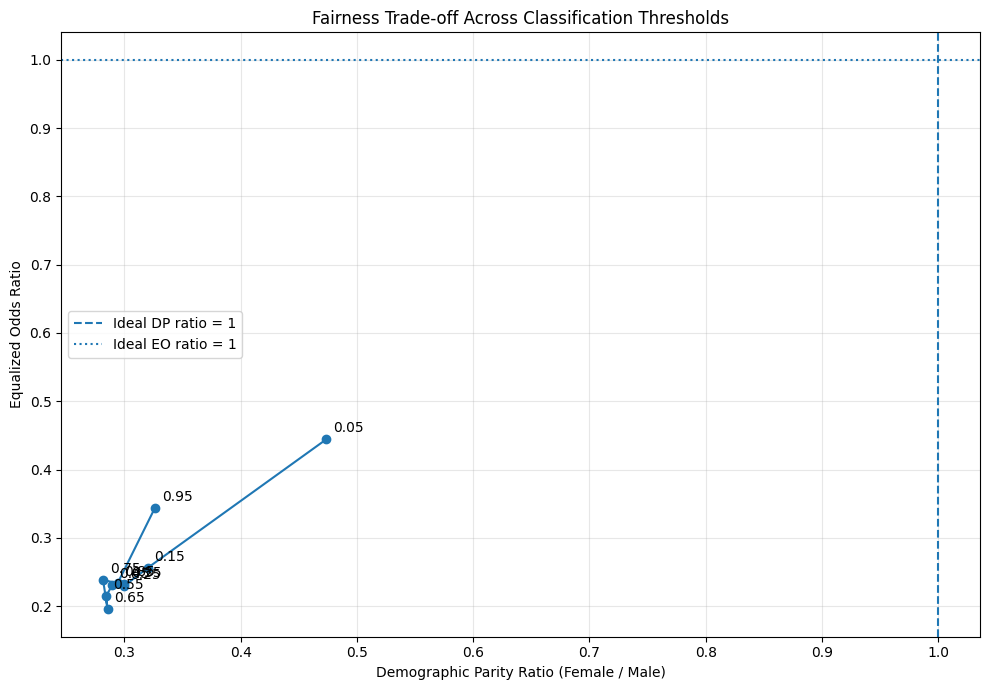

In [ ]:
# PART 2.4.3 — DP VS EO GRAPH

plot_df = fairness_table.dropna(
    subset=["DP_Ratio", "EO_Ratio"]
).copy()

plt.figure(figsize=(10, 7))

plt.plot(
    plot_df["DP_Ratio"],
    plot_df["EO_Ratio"],
    marker="o"
)

for _, row in plot_df.iterrows():
    plt.annotate(
        f'{row["Threshold"]:.2f}',
        (row["DP_Ratio"], row["EO_Ratio"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.axvline(1, linestyle="--", label="Ideal DP ratio = 1")
plt.axhline(1, linestyle=":", label="Ideal EO ratio = 1")

plt.xlabel("Demographic Parity Ratio (Female / Male)")
plt.ylabel("Equalized Odds Ratio")
plt.title("Fairness Trade-off Across Classification Thresholds")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# PART 2.4.4 — IDENTIFY THRESHOLDS CLOSEST TO IDEAL RATIOS

fairness_table["DP_Distance"] = abs(
    fairness_table["DP_Ratio"] - 1
)

fairness_table["EO_Distance"] = abs(
    fairness_table["EO_Ratio"] - 1
)

fairness_table["Combined_Distance"] = np.sqrt(
    fairness_table["DP_Distance"]**2 +
    fairness_table["EO_Distance"]**2
)

print("Thresholds closest to DP parity:")
display(
    fairness_table.sort_values("DP_Distance")[
        ["Threshold", "DP_Ratio", "EO_Ratio", "PP_Ratio"]
    ].head(3).round(4)
)

print("\nThresholds closest to EO parity:")
display(
    fairness_table.sort_values("EO_Distance")[
        ["Threshold", "DP_Ratio", "EO_Ratio", "PP_Ratio"]
    ].head(3).round(4)
)

print("\nThresholds closest to both ratios jointly:")
display(
    fairness_table.sort_values("Combined_Distance")[
        ["Threshold", "DP_Ratio", "EO_Ratio", "PP_Ratio"]
    ].head(3).round(4)
)

Thresholds closest to DP parity:


,Threshold,DP_Ratio,EO_Ratio,PP_Ratio
0,0.05,0.4735,0.4441,0.7205
9,0.95,0.3261,0.3433,0.9912
1,0.15,0.3199,0.2558,0.9786



Thresholds closest to EO parity:


,Threshold,DP_Ratio,EO_Ratio,PP_Ratio
0,0.05,0.4735,0.4441,0.7205
9,0.95,0.3261,0.3433,0.9912
1,0.15,0.3199,0.2558,0.9786



Thresholds closest to both ratios jointly:


,Threshold,DP_Ratio,EO_Ratio,PP_Ratio
0,0.05,0.4735,0.4441,0.7205
9,0.95,0.3261,0.3433,0.9912
1,0.15,0.3199,0.2558,0.9786
